# Speaker Recognition from Speech

**Dataset:** [Speaker Recognition Audio Dataset (Kaggle)](https://www.kaggle.com/datasets/vjcalling/speaker-recognition-audio-dataset)

**Two protocols are implemented:**
- **Closed-set recognition** — the same speakers appear in training, validation and test. Utterances are split, not speakers. Classic multi-class classification.
- **Open-set recognition (speaker verification)** — speakers are split into disjoint train / validation / test groups. A feature extractor is trained on the training speakers only; unseen (test) speakers are then verified by comparing a query embedding to enrolled speaker templates

**Classifiers explored:** SVM and Random Forest on handcrafted statistical features, a CNN on log-mel spectrograms, and an LSTM on MFCC sequences


> Environment: this notebook is written for **Google Colab**

## 1. Environment Setup

In [1]:
# Install audio-specific packages not preinstalled on Colab
!pip install -q librosa soundfile torchinfo


In [2]:
import os
import glob
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
import librosa
import librosa.display
import soundfile as sf

from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                      learning_curve)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                              roc_curve, auc, precision_recall_fscore_support)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchinfo import summary
from tqdm import tqdm

SEED = 424242
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


## 2. Data Acquisition

The dataset (**~8 GB**, ~50 speakers, `SpeakerXXXX/` folders each holding a few dozen `.wav` files) is
downloaded via **kagglehub**, which is what Kaggle's own "Download" button recommends for this dataset and
handles caching automatically (re-running the cell won't re-download if the files are already present).

In [3]:
import kagglehub

DATA_DIR = kagglehub.dataset_download("vjcalling/speaker-recognition-audio-dataset")
print("Path to dataset files:", DATA_DIR)


Using Colab cache for faster access to the 'speaker-recognition-audio-dataset' dataset.
Path to dataset files: /kaggle/input/speaker-recognition-audio-dataset


### 2.1 Dataset layout

The dataset stores audio as `SpeakerXXXX/<clip>.wav` — one folder per speaker, each with 30-55 files. A simple
`(filepath, speaker)` manifest is built

In [4]:
def build_manifest(root_dir, extensions=(".wav", ".flac", ".mp3")):
    """Walk the dataset directory and build a DataFrame of (filepath, speaker)."""
    records = []
    for dirpath, _, filenames in os.walk(root_dir):
        for fname in filenames:
            if fname.lower().endswith(extensions):
                speaker = os.path.basename(dirpath)
                records.append({"filepath": os.path.join(dirpath, fname), "speaker": speaker})
    return pd.DataFrame(records)

manifest = build_manifest(DATA_DIR)
print(f"Found {len(manifest)} audio files from {manifest['speaker'].nunique()} speakers")
manifest.head()


Found 2511 audio files from 50 speakers


,filepath,speaker
0,/kaggle/input/speaker-recognition-audio-datase...,Speaker0043
1,/kaggle/input/speaker-recognition-audio-datase...,Speaker0043
2,/kaggle/input/speaker-recognition-audio-datase...,Speaker0043
3,/kaggle/input/speaker-recognition-audio-datase...,Speaker0043
4,/kaggle/input/speaker-recognition-audio-datase...,Speaker0043


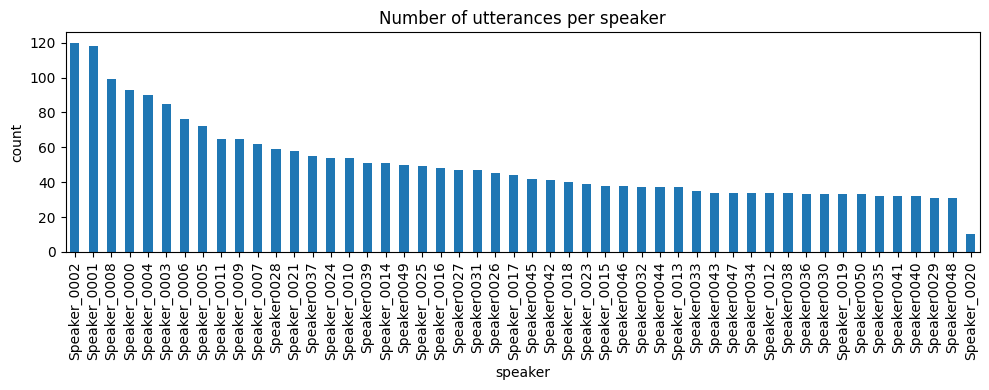

count     50.000000
mean      50.220000
std       22.926048
min       10.000000
25%       34.000000
50%       43.000000
75%       57.250000
max      120.000000
Name: count, dtype: float64


In [5]:
# Basic dataset statistics: number of utterances per speaker
counts = manifest["speaker"].value_counts()
plt.figure(figsize=(10, 4))
counts.plot(kind="bar")
plt.title("Number of utterances per speaker")
plt.ylabel("count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print(counts.describe())


### 2.2 Feature extraction functions

Two parallel feature representations will be built for every utterance in database

1. **Statistical feature vector** — mean & standard deviation of MFCCs (+ delta, delta-delta) and a handful
   of spectral descriptors (centroid, bandwidth, rolloff, zero-crossing rate). Used to feed the classical ML
   models (SVM, Random Forest) and the LSTM (as a per-frame sequence, without the final aggregation).
2. **Log-mel spectrogram** — a 2D time-frequency "image", fixed size via padding/truncation, used as the
   input to the CNN

In [ ]:
SAMPLE_RATE = 16000  # target sampling rate used throughout the notebook
N_MFCC = 20  # number of MFCC coefficients to extract per frame 
N_MELS = 64  # number of mel bands to use for the mel-spectrogram representation    
MAX_FRAMES = 310   # ~10s of audio at hop_length=512, sr=16000 -> pad/crop every clip to this length
MIN_DURATION_SEC = 1    # discard clips shorter than this


def load_audio_quality(path, sr=SAMPLE_RATE):
    y, _ = librosa.load(path, sr=sr, mono=True)
    duration = librosa.get_duration(y=y, sr=SAMPLE_RATE)
    if duration < MIN_DURATION_SEC:
        return None
    y_trimmed, _ = librosa.effects.trim(y, top_db=25)
    min_len = SAMPLE_RATE // 4  # skip near-empty clips (< 0.25s)
    if len(y_trimmed) < min_len:
        return None
    return y

def extract_mfcc_sequence(y, sr=SAMPLE_RATE, n_mfcc=N_MFCC):
    """Frame-level MFCC + delta + delta-delta sequence. Shape: (n_frames, 3*n_mfcc)."""
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
    d1 = librosa.feature.delta(mfcc)
    d2 = librosa.feature.delta(mfcc, order=2)
    feats = np.concatenate([mfcc, d1, d2], axis=0)   # (3*n_mfcc, n_frames)
    return feats.T                                    # (n_frames, 3*n_mfcc)

def pad_or_crop(arr, max_len):
    """Pad (with zeros) or crop the time axis (axis 0) of a 2D array to a fixed length."""
    n = arr.shape[0]
    if n >= max_len:
        return arr[:max_len]
    pad_width = max_len - n
    return np.pad(arr, ((0, pad_width), (0, 0)), mode="constant")

def extract_statistical_features(y, sr=SAMPLE_RATE):
    """Aggregate MFCC/delta/delta-delta + spectral descriptors into one fixed-length vector per utterance."""
    mfcc_seq = extract_mfcc_sequence(y, sr)  # (n_frames, 3*N_MFCC)

    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)[0]
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)[0]
    zcr = librosa.feature.zero_crossing_rate(y)[0]

    parts = [mfcc_seq.mean(axis=0), mfcc_seq.std(axis=0)]
    for spec_feat in (centroid, bandwidth, rolloff, zcr):
        parts.append(np.array([spec_feat.mean(), spec_feat.std()]))

    return np.concatenate(parts)

def extract_melspectrogram(y, sr=SAMPLE_RATE, n_mels=N_MELS, max_frames=MAX_FRAMES):
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=n_mels)
    S_db = librosa.power_to_db(S, ref=np.max)
    S_db = S_db.T                              # (n_frames, n_mels)
    S_db = pad_or_crop(S_db, max_frames)       # (max_frames, n_mels)
    # normalize to [0, 1] per-clip
    S_db = (S_db - S_db.min()) / (S_db.max() - S_db.min() + 1e-8)
    return S_db.T                              # (n_mels, max_frames) -> "image"-like layout

def build_stat_feature_names(n_mfcc=N_MFCC):
    names = []
    for stat in ("mean", "std"):
        for band in ("mfcc", "mfcc_delta", "mfcc_delta2"):
            names += [f"{band}{i}_{stat}" for i in range(n_mfcc)]
    for spec in ("centroid", "bandwidth", "rolloff", "zcr"):
        names += [f"{spec}_mean", f"{spec}_std"]
    return names

feature_names = build_stat_feature_names()


### 2.3 Holding out a case-study sample

One utterance is set aside before any quality filtering, feature extraction, splitting, or model training. This is the sample used later, in the Section 5.2.1 case study, to walk through exactly how the extracted features feed into a prediction.

`load_audio_quality()` applies the same duration/silence checks used by the main extraction pass, so a
clip that would itself have failed quality filtering can't silently become the case study; if the first
draw fails, the cell retries with a new random draw (a fresh seed each attempt) until it finds a usable
one.

In [7]:
case_study_row = manifest.sample(n=1, random_state=SEED).iloc[0]
case_study_audio = load_audio_quality(case_study_row["filepath"])

n_tries = 0
while case_study_audio is None:
    print("Invalid sample: trying with another one")
    n_tries += 1
    case_study_row = manifest.sample(n=1, random_state=SEED + n_tries).iloc[0]
    case_study_audio = load_audio_quality(case_study_row["filepath"])

case_study_idx = case_study_row.name

case_study_stat = extract_statistical_features(case_study_audio)
case_study_mel = extract_melspectrogram(case_study_audio)
case_study_seq = pad_or_crop(extract_mfcc_sequence(case_study_audio), MAX_FRAMES)  # for the LSTM case study
case_study_true_speaker = case_study_row["speaker"]

print(f"Held out for the Section 5.2.1 case study:")
print(f"  filepath: {case_study_row['filepath']}")
print(f"  speaker:  {case_study_true_speaker}")
print(f"  duration: {len(case_study_audio) / SAMPLE_RATE:.2f}s")


Held out for the Section 5.2.1 case study:
  filepath: /kaggle/input/speaker-recognition-audio-dataset/50_speakers_audio_data/Speaker0033/Speaker0033_019.wav
  speaker:  Speaker0033
  duration: 60.00s


### 2.4 Optional subsampling for fast iteration

For quick iteration while developing/debugging the rest of the pipeline, `MAX_FILES_PER_SPEAKER` caps how
many files per speaker go through the (relatively slow) quality-check + extraction pass below. Set it to
`None` for the final full run used to produce reported results.

In [8]:
MAX_FILES_PER_SPEAKER = None  # e.g. set to 15 for a fast debug run, None for the full dataset

if MAX_FILES_PER_SPEAKER is not None:
    manifest_run = (manifest.groupby("speaker", group_keys=False)
                     .apply(lambda g: g.sample(min(len(g), MAX_FILES_PER_SPEAKER), random_state=SEED)))
else:
    manifest_run = manifest

print(f"Using {len(manifest_run)} files for the quality check + extraction pass")


Using 2511 files for the quality check + extraction pass


### 2.5 Audio quality filtering & feature extraction (single pass)

Not every remaining file is necessarily usable: some clips can be too short, silent, or corrupted. Each usable file is loaded, its quality stats are recorded and its features are extracted.

Speaker-level filtering: drop speakers with too few (`MIN_RECORDS`) usable utterances to build a reliable
train/val/test split.

In [9]:
MIN_RECORDS = 10          # minimum usable utterances required to keep a speaker

def extract_all_features(manifest_df, skip_index=None):
    """Single pass: for each file, load once, record quality stats, and (if it passes) extract features.
    `skip_index` (the case-study row's original index, set in Section 2.3) is skipped here without
    being decoded a second time -- it was already loaded and validated there.
    """
    quality_records, X_stat, X_mel, X_seq, y_labels = [], [], [], [], []

    for idx, row in tqdm(manifest_df.iterrows(), total=len(manifest_df), desc="Quality check + extraction"):
        if idx == skip_index:
            continue
        try:
            y = load_audio_quality(row["filepath"])
            if y is None:
                continue

            rms = librosa.feature.rms(y=y)[0]
            intervals = librosa.effects.split(y, top_db=25)
            voiced = sum(e - s for s, e in intervals)
            silence_ratio = 1.0 - (voiced / len(y) if len(y) > 0 else 0.0)
            duration = librosa.get_duration(y=y, sr=SAMPLE_RATE)
            quality_records.append({"duration": duration, "rms_mean": float(rms.mean()),
                                     "silence_ratio": silence_ratio,
                                     "filepath": row["filepath"], "speaker": row["speaker"]})

            X_stat.append(extract_statistical_features(y))
            X_mel.append(extract_melspectrogram(y))
            X_seq.append(pad_or_crop(extract_mfcc_sequence(y), MAX_FRAMES))
            y_labels.append(row["speaker"])
        except Exception as e:
            print(f"Skipping {row['filepath']}: {type(e).__name__}: {e}")

    return (pd.DataFrame(quality_records), np.array(X_stat), np.array(X_mel), np.array(X_seq),
            np.array(y_labels))


quality_df, X_stat, X_mel, X_seq, y_labels = extract_all_features(manifest_run, skip_index=case_study_idx)

# speaker-level filtering, now that every file has been seen: drop speakers with too few usable utterances
label_counts = pd.Series(y_labels).value_counts()
kept_speakers = label_counts[label_counts >= MIN_RECORDS].index
keep_mask = np.isin(y_labels, kept_speakers)

X_stat, X_mel, X_seq, y_labels = X_stat[keep_mask], X_mel[keep_mask], X_seq[keep_mask], y_labels[keep_mask]
quality_df = quality_df[quality_df["speaker"].isin(kept_speakers)].reset_index(drop=True)

le = LabelEncoder()
y_enc = le.fit_transform(y_labels)
num_classes = len(le.classes_)

print(f"Speakers kept: {len(kept_speakers)} / {label_counts.shape[0]}  "
      f"(dropped speakers with < {MIN_RECORDS} usable recordings)")
print("X_stat:", X_stat.shape, " X_mel:", X_mel.shape, " X_seq:", X_seq.shape)
print("Number of speakers (classes):", num_classes)

# cache to disk so features don't need to be recomputed on every run
np.save("X_stat.npy", X_stat)
np.save("X_mel.npy", X_mel)
np.save("X_seq.npy", X_seq)
np.save("y_enc.npy", y_enc)


Quality check + extraction: 100%|██████████| 2511/2511 [21:04<00:00,  1.99it/s]


Speakers kept: 50 / 50  (dropped speakers with < 10 usable recordings)
X_stat: (2510, 128)  X_mel: (2510, 64, 310)  X_seq: (2510, 310, 60)
Number of speakers (classes): 50


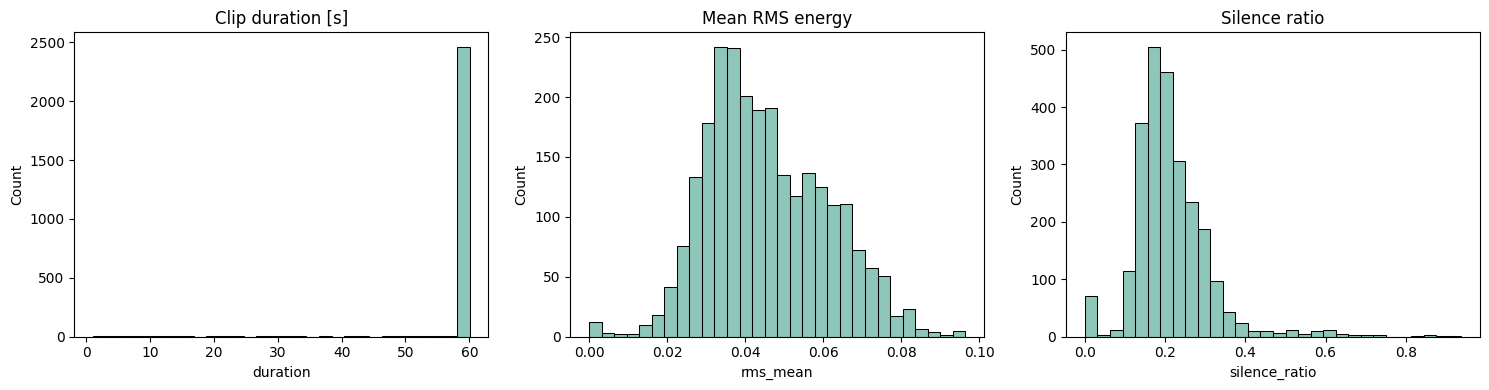

In [10]:
# Visualize the quality metrics that drove the filtering decision
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sn.histplot(quality_df["duration"], bins=30, ax=axes[0], color="#69b3a2")
axes[0].set_title("Clip duration [s]")
sn.histplot(quality_df["rms_mean"], bins=30, ax=axes[1], color="#69b3a2")
axes[1].set_title("Mean RMS energy")
sn.histplot(quality_df["silence_ratio"], bins=30, ax=axes[2], color="#69b3a2")
axes[2].set_title("Silence ratio")
plt.tight_layout()
plt.show()


### 2.6 Per-speaker quality breakdown

The aggregate histograms above show the overall shape of the dataset, but not whether quality varies
systematically *by speaker* — e.g. a speaker recorded on a noisier device or a quieter microphone would show
up as a shifted cluster here, which matters because it could let a classifier learn "recording conditions"
as a shortcut for speaker identity rather than actual voice characteristics. With ~50 speakers, a boxplot
across all of them at once is unreadable, so this is restricted to the 10 speakers with the most recordings
(after the quality/`MIN_RECORDS` filtering above, so this reflects what the models will actually train on).

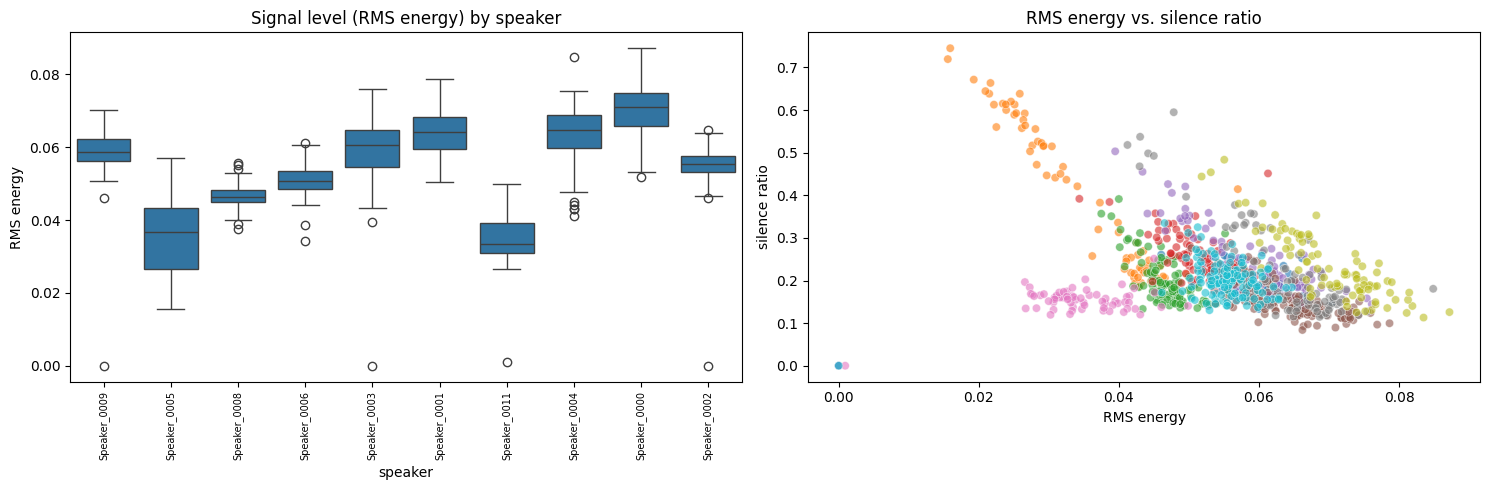

In [11]:
top_by_count = quality_df["speaker"].value_counts().nlargest(10).index
quality_top = quality_df[quality_df["speaker"].isin(top_by_count)]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. RMS energy distribution by speaker
sn.boxplot(data=quality_top, x="speaker", y="rms_mean", ax=axes[0])
axes[0].tick_params(axis="x", rotation=90, labelsize=7)
axes[0].set_title("Signal level (RMS energy) by speaker")
axes[0].set_ylabel("RMS energy")

# 2. RMS vs. silence ratio, colored by speaker - flags speakers whose clips are unusually quiet/silent
sn.scatterplot(data=quality_top, x="rms_mean", y="silence_ratio", hue="speaker",
                alpha=0.6, ax=axes[1], legend=False)
axes[1].set_title("RMS energy vs. silence ratio")
axes[1].set_xlabel("RMS energy"); axes[1].set_ylabel("silence ratio")

plt.tight_layout()
plt.show()


## 3. Data Exploration

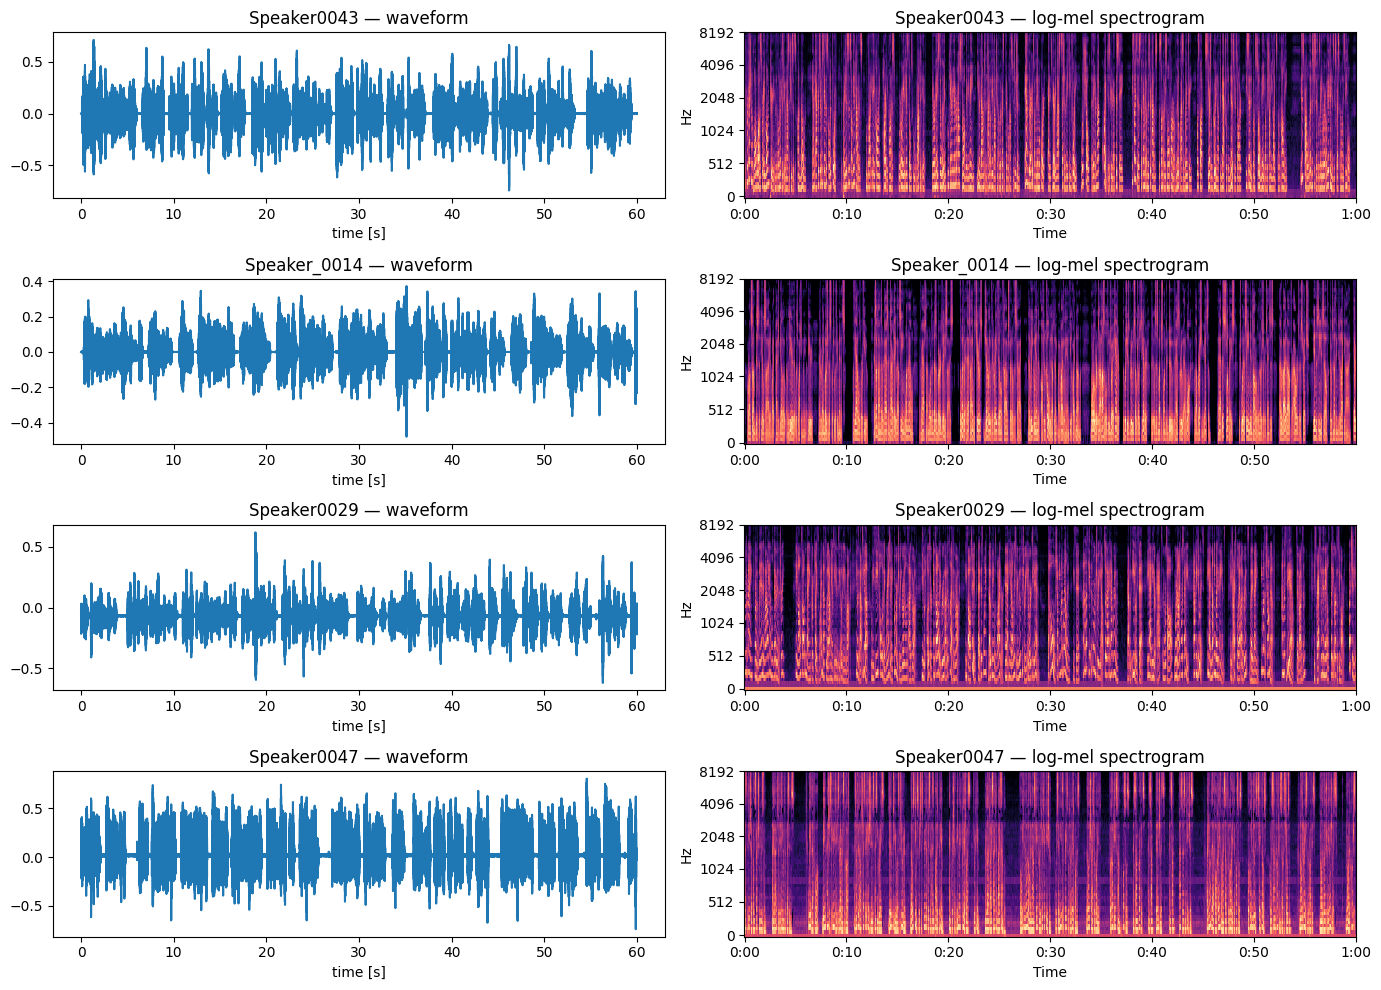

In [12]:
# Plot waveform + log-mel spectrogram for one sample per speaker (first 4 speakers, for readability)
fig, axes = plt.subplots(4, 2, figsize=(14, 10))
for i, spk in enumerate(quality_df["speaker"].unique()[:4]):
    fpath = quality_df[quality_df["speaker"] == spk].iloc[0]["filepath"]
    y = load_audio_quality(fpath)

    axes[i, 0].plot(np.linspace(0, len(y) / SAMPLE_RATE, len(y)), y)
    axes[i, 0].set_title(f"{spk} — waveform")
    axes[i, 0].set_xlabel("time [s]")

    S = librosa.feature.melspectrogram(y=y, sr=SAMPLE_RATE, n_mels=64)
    S_db = librosa.power_to_db(S, ref=np.max)
    img = librosa.display.specshow(S_db, sr=SAMPLE_RATE, x_axis="time", y_axis="mel", ax=axes[i, 1])
    axes[i, 1].set_title(f"{spk} — log-mel spectrogram")

plt.tight_layout()
plt.show()


## 4. Feature separability check: do speakers actually look different?

Before training anything, it's worth visually confirming the modeling assumption itself: do the extracted
statistical features actually vary by speaker, or would a classifier be starting from noise? Boxplots of
every one of the 128 features across all ~50 speakers would be unreadable, so this is restricted to a
handful of speakers and an evenly-spaced subset of features (a mix of MFCC means/stds and the spectral
descriptors) — enough to sanity-check separability.

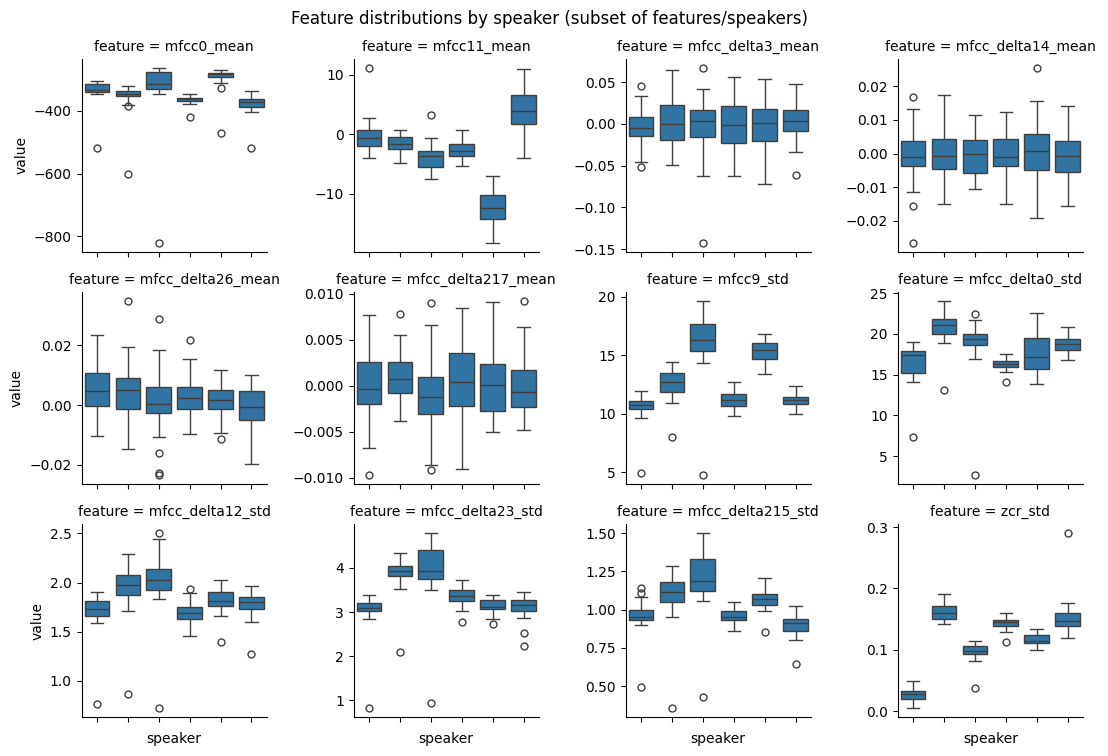

In [13]:
assert len(feature_names) == X_stat.shape[1]

# small subset of speakers and evenly-spaced features, purely for readability
speaker_subset = le.classes_[:6]
feature_idx_subset = np.linspace(0, X_stat.shape[1] - 1, 12).astype(int)

mask = np.isin(y_labels, speaker_subset)
plot_df = pd.DataFrame(X_stat[mask][:, feature_idx_subset],
                        columns=[feature_names[i] for i in feature_idx_subset])
plot_df["speaker"] = y_labels[mask]
plot_long = plot_df.melt(id_vars="speaker", var_name="feature", value_name="value")

g = sn.catplot(data=plot_long, x="speaker", y="value", col="feature", col_wrap=4,
               kind="box", sharey=False, height=2.5, aspect=1.1)
g.set_xticklabels(rotation=90)
g.fig.suptitle("Feature distributions by speaker (subset of features/speakers)", y=1.02)
plt.show()


**What to look for:** features where the boxes barely overlap across speakers (e.g. often
lower-order MFCCs and spectral centroid, which track overall vocal-tract shape) are strong individual
discriminators; features with heavily overlapping boxes across all speakers are likely doing little work on
their own and rely on combination with other features (which is exactly what the SVM/RF/CNN are trained to
exploit).

## 5. Closed-Set Recognition

Speakers are the same across training, validation and test — only the utterances are split
(60% train / 20% validation / 20% test, stratified by speaker so every speaker is represented in every set).

In [14]:
X_tr_stat, X_tmp_stat, X_tr_mel, X_tmp_mel, X_tr_seq, X_tmp_seq, y_tr, y_tmp = train_test_split(
    X_stat, X_mel, X_seq, y_enc, test_size=0.4, stratify=y_enc, random_state=SEED)

X_val_stat, X_te_stat, X_val_mel, X_te_mel, X_val_seq, X_te_seq, y_val, y_te = train_test_split(
    X_tmp_stat, X_tmp_mel, X_tmp_seq, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)

print("Train:", X_tr_stat.shape[0], " Val:", X_val_stat.shape[0], " Test:", X_te_stat.shape[0])


Train: 1506  Val: 502  Test: 502


### 5.1 Baseline: SVM and Random Forest on statistical features

`GridSearchCV` (5-fold stratified cross-validation on the training set) is used to search over a small grid for each model.

In [15]:
scaler = StandardScaler()
X_tr_stat_s = scaler.fit_transform(X_tr_stat)
X_val_stat_s = scaler.transform(X_val_stat)
X_te_stat_s = scaler.transform(X_te_stat)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

param_grids = {
    "SVM": (
        SVC(probability=True, random_state=SEED),
        {"C": [1, 10, 50], "kernel": ["linear", "rbf"], "gamma": ["scale", "auto"]},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=-1),
        {"n_estimators": [200, 300], "max_depth": [None, 20, 40], "min_samples_split": [2, 5]},
    ),
}

best_classical_models = {}
for name, (estimator, grid) in param_grids.items():
    search = GridSearchCV(estimator, grid, cv=cv, scoring="accuracy", n_jobs=-1)
    search.fit(X_tr_stat_s, y_tr)
    best_classical_models[name] = search.best_estimator_
    print(f"{name}: best params = {search.best_params_}  |  best CV accuracy = {search.best_score_:.3f}")

svm_clf = best_classical_models["SVM"]
rf_clf = best_classical_models["Random Forest"]

for name, clf in best_classical_models.items():
    val_acc = accuracy_score(y_val, clf.predict(X_val_stat_s))
    test_acc = accuracy_score(y_te, clf.predict(X_te_stat_s))
    print(f"{name:15s} | val acc: {val_acc:.3f} | test acc: {test_acc:.3f}")


SVM: best params = {'C': 1, 'gamma': 'scale', 'kernel': 'linear'}  |  best CV accuracy = 0.967
Random Forest: best params = {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}  |  best CV accuracy = 0.963
SVM             | val acc: 0.972 | test acc: 0.976
Random Forest   | val acc: 0.960 | test acc: 0.978


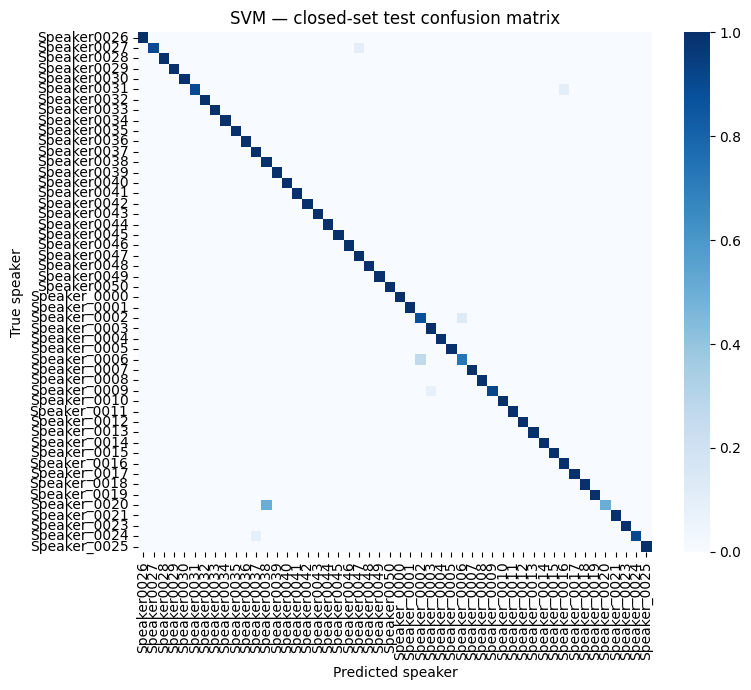

              precision    recall  f1-score   support

 Speaker0026       1.00      1.00      1.00         9
 Speaker0027       1.00      0.90      0.95        10
 Speaker0028       1.00      1.00      1.00        12
 Speaker0029       1.00      1.00      1.00         6
 Speaker0030       1.00      1.00      1.00         6
 Speaker0031       1.00      0.90      0.95        10
 Speaker0032       1.00      1.00      1.00         7
 Speaker0033       1.00      1.00      1.00         7
 Speaker0034       1.00      1.00      1.00         7
 Speaker0035       1.00      1.00      1.00         7
 Speaker0036       1.00      1.00      1.00         6
 Speaker0037       0.92      1.00      0.96        11
 Speaker0038       0.88      1.00      0.93         7
 Speaker0039       1.00      1.00      1.00        10
 Speaker0040       1.00      1.00      1.00         6
 Speaker0041       1.00      1.00      1.00         7
 Speaker0042       1.00      1.00      1.00         8
 Speaker0043       1.00    

In [16]:
def plot_confusion(y_true, y_pred, class_names, title):
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    plt.figure(figsize=(8, 7))
    sn.heatmap(cm_norm, xticklabels=class_names, yticklabels=class_names, cmap="Blues")
    plt.title(title)
    plt.xlabel("Predicted speaker")
    plt.ylabel("True speaker")
    plt.tight_layout()
    plt.show()

plot_confusion(y_te, svm_clf.predict(X_te_stat_s), le.classes_, "SVM — closed-set test confusion matrix")
print(classification_report(y_te, svm_clf.predict(X_te_stat_s), target_names=le.classes_))


### 5.2 CNN on log-mel spectrograms

In [ ]:
class SpectrogramDataset(Dataset):
    """PyTorch Dataset for log-mel spectrograms and speaker labels."""
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32).unsqueeze(1)  # (N, 1, n_mels, max_frames)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_loader = DataLoader(SpectrogramDataset(X_tr_mel, y_tr), batch_size=32, shuffle=True)
val_loader = DataLoader(SpectrogramDataset(X_val_mel, y_val), batch_size=32, shuffle=False)
test_loader = DataLoader(SpectrogramDataset(X_te_mel, y_te), batch_size=32, shuffle=False)


In [ ]:
class SpeakerCNN(nn.Module):
    """Small 2D-CNN classifier over log-mel spectrograms.
    Four convolutional blocks, followed by a linear embedding layer and a final classification layer.
    The embedding layer can be used for open-set speaker verification (Section 5.2)."""
    def __init__(self, num_classes, embedding_dim=128):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=5, padding=2),
            nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=5, padding=2),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(), nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.embedding = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, embedding_dim),
            nn.ReLU(),
        )
        self.classifier = nn.Linear(embedding_dim, num_classes)

    def forward(self, x, return_embedding=False):
        x = self.features(x)
        emb = self.embedding(x)
        if return_embedding:
            return emb
        return self.classifier(emb)


cnn_model = SpeakerCNN(num_classes=num_classes).to(device)
summary(cnn_model, input_size=(1, 1, N_MELS, MAX_FRAMES))


Layer (type:depth-idx)                   Output Shape              Param #
SpeakerCNN                               [1, 50]                   --
├─Sequential: 1-1                        [1, 64, 4, 4]             --
│    └─Conv2d: 2-1                       [1, 16, 64, 310]          416
│    └─BatchNorm2d: 2-2                  [1, 16, 64, 310]          32
│    └─ReLU: 2-3                         [1, 16, 64, 310]          --
│    └─MaxPool2d: 2-4                    [1, 16, 32, 155]          --
│    └─Conv2d: 2-5                       [1, 32, 32, 155]          12,832
│    └─BatchNorm2d: 2-6                  [1, 32, 32, 155]          64
│    └─ReLU: 2-7                         [1, 32, 32, 155]          --
│    └─MaxPool2d: 2-8                    [1, 32, 16, 77]           --
│    └─Conv2d: 2-9                       [1, 64, 16, 77]           18,496
│    └─BatchNorm2d: 2-10                 [1, 64, 16, 77]           128
│    └─ReLU: 2-11                        [1, 64, 16, 77]           --
│    

In [ ]:
def get_embeddings(model, X):
    """Converts each audio spectrogram into a fixed-length numerical representation produced by the CNN"""
    model.eval()
    loader = DataLoader(SpectrogramDataset(X, np.zeros(len(X))), batch_size=64, shuffle=False)
    embs = []
    with torch.no_grad():
        for xb, _ in loader:
            xb = xb.to(device)
            embs.append(model(xb, return_embedding=True).cpu().numpy())
    return np.concatenate(embs, axis=0)


def train_model(model, train_loader, val_loader, epochs=25, lr=1e-3):
    """Trains model and, at the end, restores the weights from the epoch with the best
    validation accuracy (not necessarily the last epoch) -- late-training fluctuations can
    otherwise leave the model in a transiently bad state at the moment training stops, which
    would then unfairly show up in the test-set evaluation done right after this returns.

    A flat learning rate is fine early on but tends to overshoot once the model is already
    fitting well -- ReduceLROnPlateau halves the LR whenever val_loss stops improving for a few
    epochs, which damps exactly the kind of late-training val spikes a constant LR causes."""
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=3, factor=0.5)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    best_val_acc = -1.0
    best_state = None
    best_epoch = 0

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                out = model(xb)
                loss = criterion(out, yb)
                v_loss += loss.item() * xb.size(0)
                v_correct += (out.argmax(1) == yb).sum().item()
                v_total += xb.size(0)
        val_loss, val_acc = v_loss / v_total, v_correct / v_total

        history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc); history["val_acc"].append(val_acc)
        print(f"Epoch {epoch:02d}/{epochs} | train_loss {train_loss:.3f} acc {train_acc:.3f} "
              f"| val_loss {val_loss:.3f} acc {val_acc:.3f}")

        prev_lr = optimizer.param_groups[0]["lr"]
        scheduler.step(val_loss)
        new_lr = optimizer.param_groups[0]["lr"]
        if new_lr < prev_lr:
            print(f"  -> val_loss plateaued: reducing LR to {new_lr:.2e}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    print(f"Restored weights from epoch {best_epoch} (best val_acc = {best_val_acc:.3f})")

    return history


cnn_history = train_model(cnn_model, train_loader, val_loader, epochs=25)


Epoch 01/25 | train_loss 3.602 acc 0.084 | val_loss 3.500 acc 0.050
Epoch 02/25 | train_loss 2.687 acc 0.288 | val_loss 2.355 acc 0.376
Epoch 03/25 | train_loss 1.844 acc 0.511 | val_loss 1.835 acc 0.386
Epoch 04/25 | train_loss 1.281 acc 0.649 | val_loss 1.299 acc 0.578
Epoch 05/25 | train_loss 0.854 acc 0.787 | val_loss 1.411 acc 0.528
Epoch 06/25 | train_loss 0.583 acc 0.853 | val_loss 0.789 acc 0.743
Epoch 07/25 | train_loss 0.559 acc 0.841 | val_loss 1.438 acc 0.546
Epoch 08/25 | train_loss 0.375 acc 0.905 | val_loss 0.652 acc 0.785
Epoch 09/25 | train_loss 0.330 acc 0.905 | val_loss 0.412 acc 0.884
Epoch 10/25 | train_loss 0.298 acc 0.910 | val_loss 1.511 acc 0.582
Epoch 11/25 | train_loss 0.279 acc 0.918 | val_loss 0.370 acc 0.880
Epoch 12/25 | train_loss 0.273 acc 0.913 | val_loss 0.429 acc 0.859
Epoch 13/25 | train_loss 0.185 acc 0.943 | val_loss 0.596 acc 0.805
Epoch 14/25 | train_loss 0.176 acc 0.954 | val_loss 0.375 acc 0.875
Epoch 15/25 | train_loss 0.205 acc 0.934 | val_l

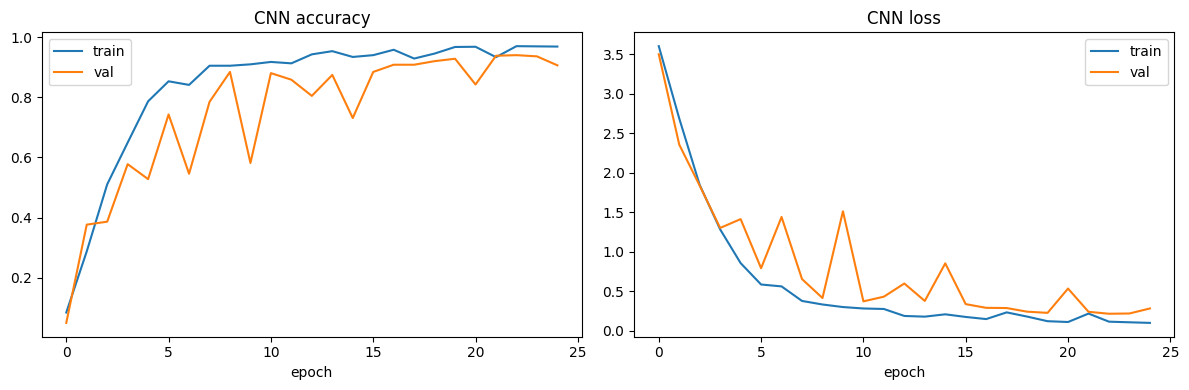

In [20]:
def plot_history(history, title_prefix=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_acc"], label="train"); axes[0].plot(history["val_acc"], label="val")
    axes[0].set_title(f"{title_prefix} accuracy"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(history["train_loss"], label="train"); axes[1].plot(history["val_loss"], label="val")
    axes[1].set_title(f"{title_prefix} loss"); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.tight_layout(); plt.show()

plot_history(cnn_history, "CNN")


CNN — test accuracy: 0.944


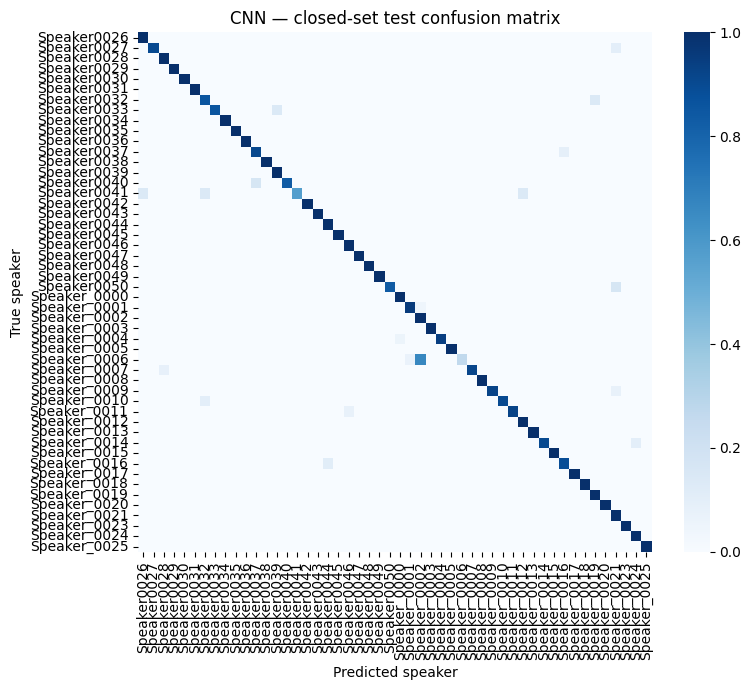

In [ ]:
def evaluate_torch_model(model, loader, class_names, title):
    """Returns (accuracy, y_true, y_pred)."""
    model.eval()
    all_preds, all_true = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            preds = model(xb).argmax(1).cpu().numpy()
            all_preds.extend(preds); all_true.extend(yb.numpy())
    acc = accuracy_score(all_true, all_preds)
    print(f"{title} — test accuracy: {acc:.3f}")
    plot_confusion(all_true, all_preds, class_names, f"{title} — closed-set test confusion matrix")
    return acc, all_true, all_preds

cnn_test_acc, cnn_y_true, cnn_y_pred = evaluate_torch_model(cnn_model, test_loader, le.classes_, "CNN")


### 5.2.1 Case study: how the held-out sample gets classified

The utterance held out all the way back in Section 2.3 is now walked through the full prediction pipeline for every model, to make the abstract "128-d feature vector" / "spectrogram" / "MFCC sequence" concrete

- **Classical models (SVM/RF):** the sample's standardized statistical feature vector drives each
  model's predicted class probabilities, shown below. 
- **CNN:** a **saliency map** is computed — the gradient of the predicted class's score with respect to
  every pixel of the input spectrogram.
- **LSTM:** predicted class probabilities on the same sample's MFCC sequence.

In [22]:
# case_study_stat / case_study_mel / case_study_true_speaker were prepared in Section 2.3-2.4,
# from the sample held out there - it never entered X_stat/X_mel/X_te_*/the scaler/any model
true_speaker = case_study_true_speaker
print(f"Case-study sample  |  true speaker: {true_speaker}")


Case-study sample  |  true speaker: Speaker0033


#### 5.2.1a Classical models: predicted probabilities for this sample

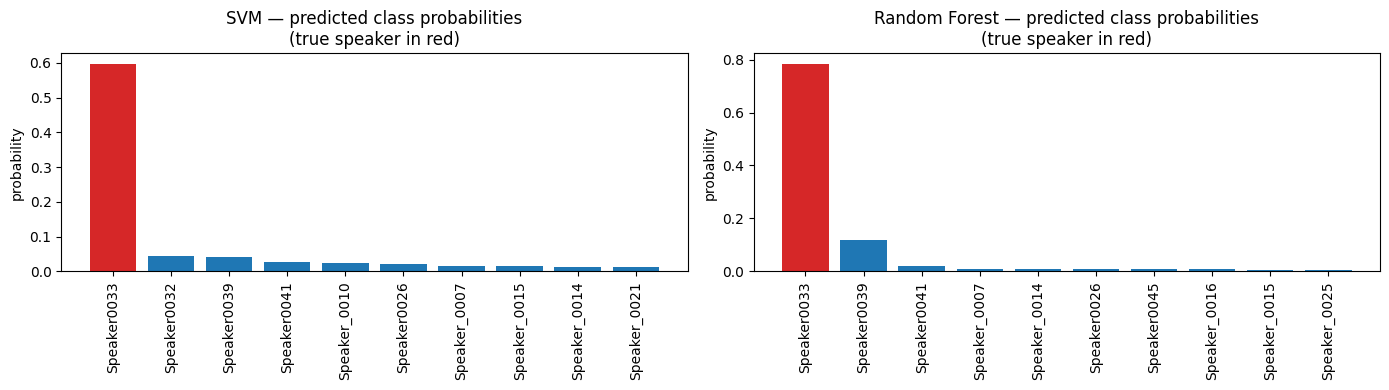

In [ ]:
sample_feat = scaler.transform(case_study_stat.reshape(1, -1))[0]  # standardize with the already-fit scaler

svm_proba = svm_clf.predict_proba(sample_feat.reshape(1, -1))[0]
rf_proba = rf_clf.predict_proba(sample_feat.reshape(1, -1))[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, proba, name in zip(axes, [svm_proba, rf_proba], ["SVM", "Random Forest"]):
    order = np.argsort(proba)[::-1][:10]
    colors = ["#d62728" if le.classes_[o] == true_speaker else "#1f77b4" for o in order]
    ax.bar(range(len(order)), proba[order], color=colors)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(le.classes_[order], rotation=90)
    ax.set_title(f"{name} — predicted class probabilities\n(true speaker in red)")
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()


#### 5.2.1b CNN: saliency map for the same held-out sample

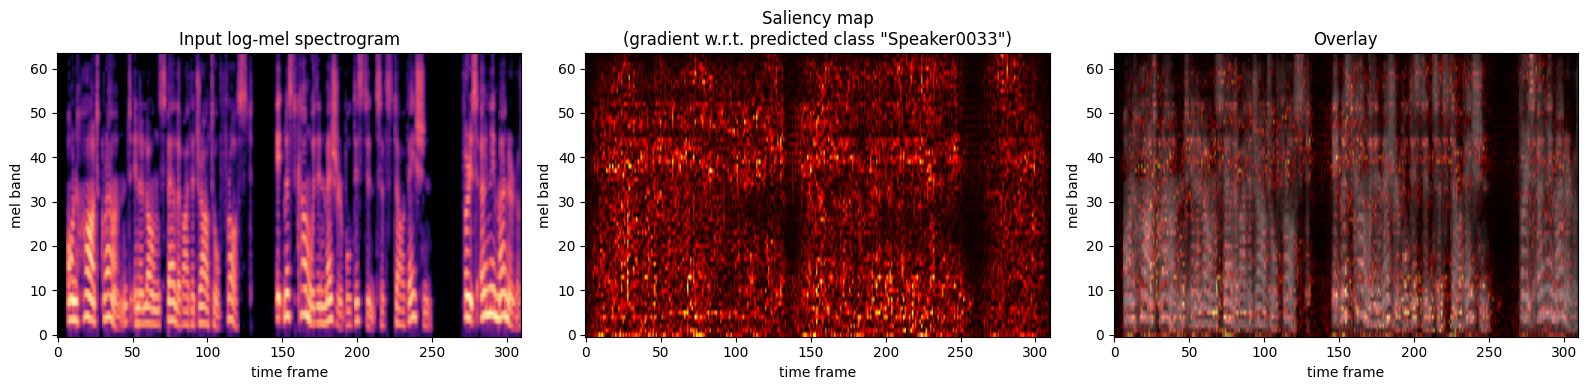

True speaker: Speaker0033  |  CNN predicted: Speaker0033  |  correct


In [24]:
cnn_model.eval()
sample_spec = torch.tensor(case_study_mel, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
sample_spec = sample_spec.to(device)
sample_spec.requires_grad_(True)

logits = cnn_model(sample_spec)
predicted_class = logits.argmax(dim=1).item()
predicted_speaker = le.inverse_transform([predicted_class])[0]

cnn_model.zero_grad()
logits[0, predicted_class].backward()

saliency = sample_spec.grad.detach().abs().cpu().numpy()[0, 0]  # (n_mels, max_frames)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].imshow(case_study_mel, origin="lower", aspect="auto", cmap="magma")
axes[0].set_title("Input log-mel spectrogram")

axes[1].imshow(saliency, origin="lower", aspect="auto", cmap="hot")
axes[1].set_title(f"Saliency map\n(gradient w.r.t. predicted class \"{predicted_speaker}\")")

axes[2].imshow(case_study_mel, origin="lower", aspect="auto", cmap="gray")
axes[2].imshow(saliency, origin="lower", aspect="auto", cmap="hot", alpha=0.5)
axes[2].set_title("Overlay")

for ax in axes:
    ax.set_xlabel("time frame"); ax.set_ylabel("mel band")
plt.tight_layout()
plt.show()

print(f"True speaker: {true_speaker}  |  CNN predicted: {predicted_speaker}  |  "
      f"{'correct' if predicted_speaker == true_speaker else 'INCORRECT'}")


**Reading the saliency map:** brighter regions are time-frequency bins the network's
predicted-class score is most sensitive to for *this specific sample* — a small perturbation there would
change the prediction the most. If the bright regions cluster around the lower mel bands during voiced
segments (as opposed to being scattered across silence/padding), that's a good sign the CNN is attending to
actual speech content rather than to artifacts or padding, which the padding/cropping step in Section 2.2
(`pad_or_crop`, `MAX_FRAMES`) introduces for short clips.

### 5.3 LSTM on MFCC sequences

Epoch 01/20 | train_loss 3.783 acc 0.044 | val_loss 3.401 acc 0.110
Epoch 02/20 | train_loss 3.217 acc 0.120 | val_loss 2.866 acc 0.161
Epoch 03/20 | train_loss 2.730 acc 0.206 | val_loss 2.391 acc 0.293
Epoch 04/20 | train_loss 2.462 acc 0.268 | val_loss 2.116 acc 0.406
Epoch 05/20 | train_loss 2.122 acc 0.349 | val_loss 1.715 acc 0.500
Epoch 06/20 | train_loss 1.803 acc 0.416 | val_loss 1.481 acc 0.586
Epoch 07/20 | train_loss 1.678 acc 0.470 | val_loss 1.352 acc 0.629
Epoch 08/20 | train_loss 1.617 acc 0.479 | val_loss 1.293 acc 0.620
Epoch 09/20 | train_loss 1.288 acc 0.579 | val_loss 1.055 acc 0.697
Epoch 10/20 | train_loss 1.181 acc 0.611 | val_loss 1.010 acc 0.659
Epoch 11/20 | train_loss 1.055 acc 0.627 | val_loss 0.832 acc 0.751
Epoch 12/20 | train_loss 0.945 acc 0.687 | val_loss 0.884 acc 0.731
Epoch 13/20 | train_loss 0.831 acc 0.723 | val_loss 0.765 acc 0.767
Epoch 14/20 | train_loss 0.942 acc 0.684 | val_loss 0.866 acc 0.699
Epoch 15/20 | train_loss 1.152 acc 0.631 | val_l

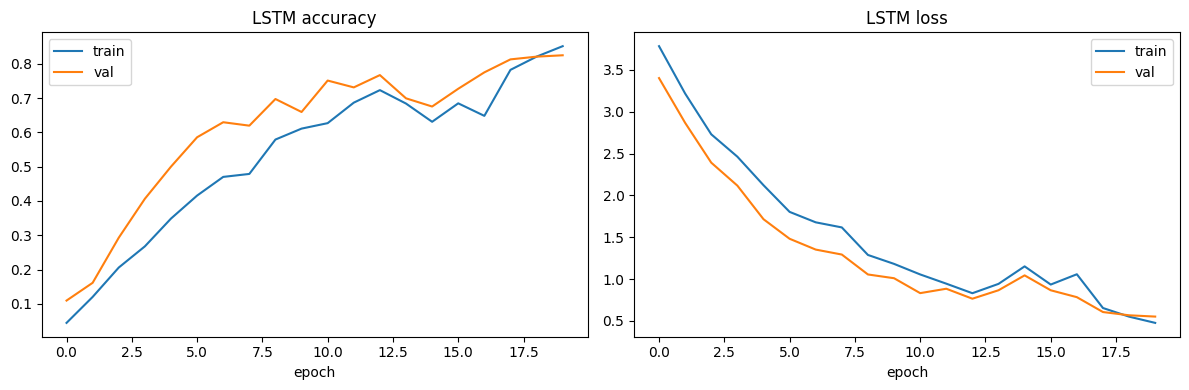

LSTM — test accuracy: 0.851


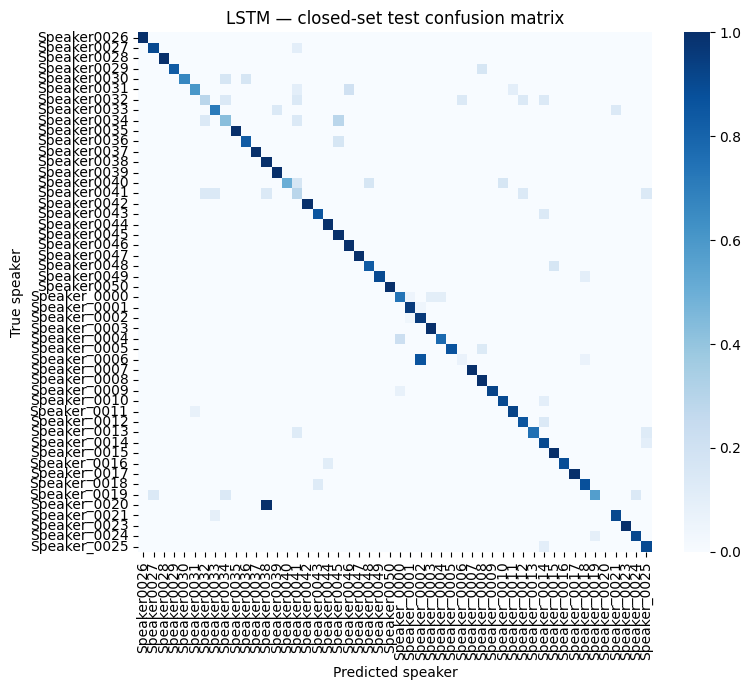

In [25]:
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)  # (N, max_frames, 3*N_MFCC)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


seq_train_loader = DataLoader(SequenceDataset(X_tr_seq, y_tr), batch_size=32, shuffle=True)
seq_val_loader = DataLoader(SequenceDataset(X_val_seq, y_val), batch_size=32, shuffle=False)
seq_test_loader = DataLoader(SequenceDataset(X_te_seq, y_te), batch_size=32, shuffle=False)


class SpeakerLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_classes=num_classes):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=2, batch_first=True, bidirectional=True)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        out, (h_n, _) = self.lstm(x)
        # concatenate last hidden state from both directions
        last = torch.cat([h_n[-2], h_n[-1]], dim=1)
        return self.classifier(last)


lstm_model = SpeakerLSTM(input_dim=X_tr_seq.shape[-1]).to(device)
lstm_history = train_model(lstm_model, seq_train_loader, seq_val_loader, epochs=20, lr=1e-3)
plot_history(lstm_history, "LSTM")
lstm_test_acc, lstm_y_true, lstm_y_pred = evaluate_torch_model(lstm_model, seq_test_loader, le.classes_, "LSTM")


### 5.3.1 Case study: LSTM prediction for the held-out sample

The same held-out utterance from Section 2.3 is now run through the trained LSTM, alongside the SVM/RF and CNN predictions already shown in Section 5.2.1

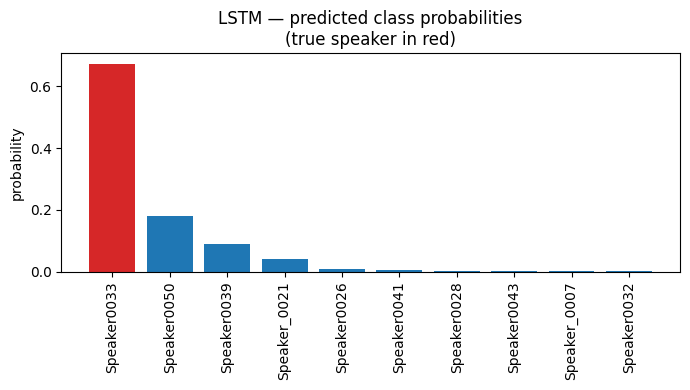

True speaker: Speaker0033  |  LSTM predicted: Speaker0033  |  correct


In [26]:
lstm_model.eval()
sample_seq = torch.tensor(case_study_seq, dtype=torch.float32).unsqueeze(0).to(device)  # (1, max_frames, 3*N_MFCC)

with torch.no_grad():
    lstm_logits = lstm_model(sample_seq)
    lstm_proba = torch.softmax(lstm_logits, dim=1).cpu().numpy()[0]

lstm_predicted_class = lstm_proba.argmax()
lstm_predicted_speaker = le.inverse_transform([lstm_predicted_class])[0]

order = np.argsort(lstm_proba)[::-1][:10]
colors = ["#d62728" if le.classes_[o] == true_speaker else "#1f77b4" for o in order]
plt.figure(figsize=(7, 4))
plt.bar(range(len(order)), lstm_proba[order], color=colors)
plt.xticks(range(len(order)), le.classes_[order], rotation=90)
plt.ylabel("probability")
plt.title("LSTM — predicted class probabilities\n(true speaker in red)")
plt.tight_layout()
plt.show()

print(f"True speaker: {true_speaker}  |  LSTM predicted: {lstm_predicted_speaker}  |  "
      f"{'correct' if lstm_predicted_speaker == true_speaker else 'INCORRECT'}")


### 5.4 Closed-set model comparison

In [27]:
# Macro-averaged precision/recall/F1 (each class weighted equally, appropriate here since the
# 50 speakers are reasonably balanced) alongside accuracy, rather than accuracy alone.
svm_y_pred = svm_clf.predict(X_te_stat_s)
rf_y_pred = rf_clf.predict(X_te_stat_s)

model_predictions = {
    "SVM": (y_te, svm_y_pred),
    "Random Forest": (y_te, rf_y_pred),
    "CNN (mel-spectrogram)": (cnn_y_true, cnn_y_pred),
    "LSTM (MFCC sequence)": (lstm_y_true, lstm_y_pred),
}

rows = []
for model_name, (y_true, y_pred) in model_predictions.items():
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    rows.append({
        "model": model_name,
        "test_accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
    })

results_closed = pd.DataFrame(rows)
results_closed


,model,test_accuracy,precision_macro,recall_macro,f1_macro
0,SVM,0.976096,0.982737,0.974810,0.976631
1,Random Forest,0.978088,0.985361,0.983286,0.983792
2,CNN (mel-spectrogram),0.944223,0.962051,0.947616,0.947347
3,LSTM (MFCC sequence),0.850598,0.838891,0.826154,0.821698


### 5.4.1 Top features by model: SVM vs. Random Forest

Which features do the two classical models rely on across the whole training set: SVM and Random Forest are
both fit directly on `X_stat`, so their importances live in the same 128-dimensional feature space and
are directly comparable feature-for-feature. The CNN and LSTM operate on different input
representations (spectrograms, raw MFCC sequences) with no equivalent per-feature-name importance, so
they can't join this particular comparison.

- **Random Forest**: `feature_importances_` (mean impurity decrease), already computed in 5.2.1a.
- **SVM**: with the linear kernel selected by GridSearchCV, `coef_` gives an exact per-feature weight for
  every one-vs-one class pair; averaging `|coef_|` over all pairs gives a global per-feature importance
  directly comparable in spirit to the RF version.

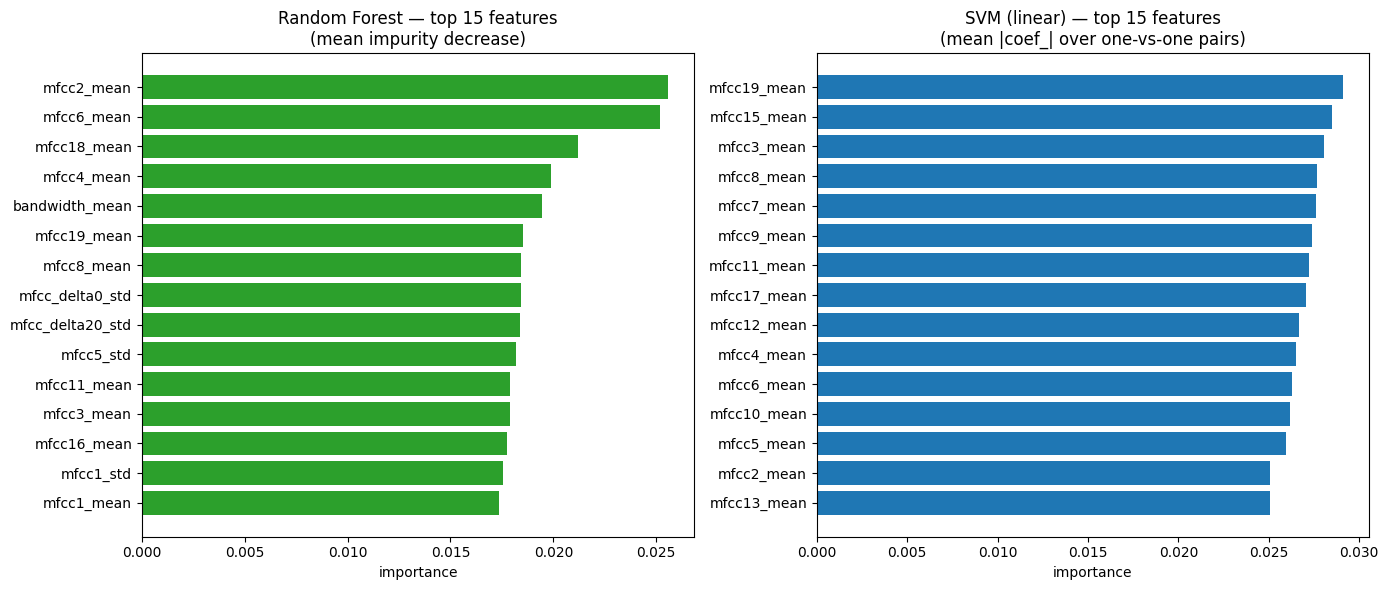

Overlap: 7 / 15 features shared between the two top-15 lists
Shared features: ['mfcc11_mean', 'mfcc19_mean', 'mfcc2_mean', 'mfcc3_mean', 'mfcc4_mean', 'mfcc6_mean', 'mfcc8_mean']
RF-only (top 15): ['bandwidth_mean', 'mfcc16_mean', 'mfcc18_mean', 'mfcc1_mean', 'mfcc1_std', 'mfcc5_std', 'mfcc_delta0_std', 'mfcc_delta20_std']
SVM-only (top 15): ['mfcc10_mean', 'mfcc12_mean', 'mfcc13_mean', 'mfcc15_mean', 'mfcc17_mean', 'mfcc5_mean', 'mfcc7_mean', 'mfcc9_mean']


In [28]:
rf_importance = rf_clf.feature_importances_
svm_importance = np.abs(svm_clf.coef_).mean(axis=0)  # coef_: (n_ovo_pairs, n_features) for linear SVC

rf_top15 = np.argsort(rf_importance)[::-1][:15]
svm_top15 = np.argsort(svm_importance)[::-1][:15]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh([feature_names[i] for i in rf_top15][::-1], rf_importance[rf_top15][::-1], color="#2ca02c")
axes[0].set_title("Random Forest — top 15 features\n(mean impurity decrease)")
axes[0].set_xlabel("importance")

axes[1].barh([feature_names[i] for i in svm_top15][::-1], svm_importance[svm_top15][::-1], color="#1f77b4")
axes[1].set_title("SVM (linear) — top 15 features\n(mean |coef_| over one-vs-one pairs)")
axes[1].set_xlabel("importance")
plt.tight_layout()
plt.show()

shared = set(rf_top15) & set(svm_top15)
print(f"Overlap: {len(shared)} / 15 features shared between the two top-15 lists")
print("Shared features:", sorted(feature_names[i] for i in shared))
print("RF-only (top 15):", sorted(feature_names[i] for i in set(rf_top15) - set(svm_top15)))
print("SVM-only (top 15):", sorted(feature_names[i] for i in set(svm_top15) - set(rf_top15)))


### 5.5 Learning curves

Learning curves show train vs. cross-validation accuracy as a function of training-set size, for the two
classical models. This helps diagnose whether a model is **overfitting** (large, non-closing gap between
train and CV curves — more data or a simpler model would help) or **underfitting** (both curves plateau at
a low, similar accuracy — the model or features are the bottleneck rather than the amount of data).

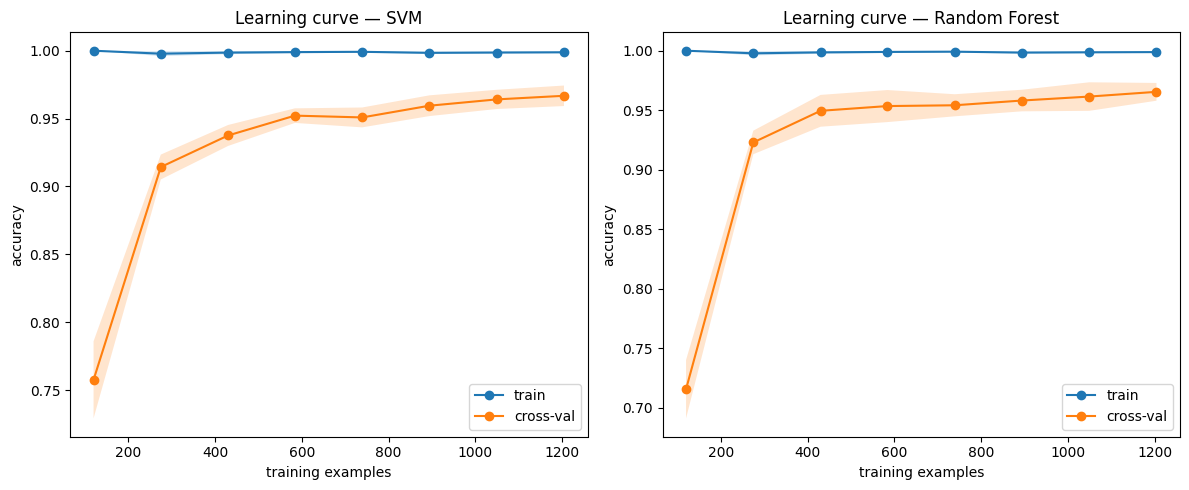

In [29]:
def plot_learning_curves(models_dict, X, y, cv=5, scoring="accuracy"):
    train_sizes = np.linspace(0.1, 1.0, 8)
    fig, axes = plt.subplots(1, len(models_dict), figsize=(6 * len(models_dict), 5))
    if len(models_dict) == 1:
        axes = [axes]

    for ax, (name, model) in zip(axes, models_dict.items()):
        sizes, train_scores, val_scores = learning_curve(
            model, X, y, cv=cv, scoring=scoring, train_sizes=train_sizes,
            n_jobs=-1, random_state=SEED)

        train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
        val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

        ax.plot(sizes, train_mean, "o-", label="train")
        ax.fill_between(sizes, train_mean - train_std, train_mean + train_std, alpha=0.2)
        ax.plot(sizes, val_mean, "o-", label="cross-val")
        ax.fill_between(sizes, val_mean - val_std, val_mean + val_std, alpha=0.2)
        ax.set_title(f"Learning curve — {name}")
        ax.set_xlabel("training examples")
        ax.set_ylabel(scoring)
        ax.legend()

    plt.tight_layout()
    plt.show()

plot_learning_curves(best_classical_models, X_tr_stat_s, y_tr, cv=cv)


## 6. Open-Set Recognition (Speaker Verification)

Here speakers themselves — not just utterances — are split into disjoint groups:
- **Train speakers**: used to train the embedding extractor.
- **Validation speakers**: used to tune the acceptance threshold.
- **Test speakers**: this is what makes the protocol "open-set": the
  system must recognize/verify speakers it has never been trained on.

The approach (a simplified version of the "d-vector" idea from the speaker-recognition literature):
train a classifier CNN on the training speakers only, then reuse its embedding layer as a fixed-size
speaker representation for arbitrary (even unseen) speakers. New speakers are enrolled by averaging
the embeddings of a few of their utterances into a template; verification is then a similarity comparison
between a query embedding and a template.

In [30]:
all_speakers = np.array(le.classes_)
n_speakers = len(all_speakers)

rng = np.random.RandomState(SEED)
shuffled_speakers = rng.permutation(all_speakers)

n_train_spk = int(0.6 * n_speakers)
n_val_spk = int(0.2 * n_speakers)

train_speakers = set(shuffled_speakers[:n_train_spk])
val_speakers = set(shuffled_speakers[n_train_spk:n_train_spk + n_val_spk])
test_speakers = set(shuffled_speakers[n_train_spk + n_val_spk:])

print(f"Train speakers: {len(train_speakers)} | Val speakers: {len(val_speakers)} | "
      f"Test speakers: {len(test_speakers)}")
assert train_speakers.isdisjoint(val_speakers) and train_speakers.isdisjoint(test_speakers) \
       and val_speakers.isdisjoint(test_speakers)


Train speakers: 30 | Val speakers: 10 | Test speakers: 10


### 6.1 Training an embedding extractor

Train-speaker utterances are masked out and used for a proxy classification task, thus forcing the CNN's penultimate layer to learn a representation that separates speakers well. That layer
is then reused as the embedding for enrollment/verification, including for speakers never seen here.

Epoch 01/25 | train_loss 2.939 acc 0.158 | val_loss 4.005 acc 0.068
Epoch 02/25 | train_loss 1.859 acc 0.462 | val_loss 1.491 acc 0.586
Epoch 03/25 | train_loss 1.068 acc 0.691 | val_loss 1.851 acc 0.419
Epoch 04/25 | train_loss 0.752 acc 0.775 | val_loss 1.511 acc 0.468
Epoch 05/25 | train_loss 0.543 acc 0.831 | val_loss 0.742 acc 0.761
Epoch 06/25 | train_loss 0.458 acc 0.851 | val_loss 0.601 acc 0.851
Epoch 07/25 | train_loss 0.348 acc 0.883 | val_loss 1.739 acc 0.523
Epoch 08/25 | train_loss 0.293 acc 0.895 | val_loss 0.460 acc 0.833
Epoch 09/25 | train_loss 0.277 acc 0.898 | val_loss 0.334 acc 0.865
Epoch 10/25 | train_loss 0.233 acc 0.923 | val_loss 0.429 acc 0.856
Epoch 11/25 | train_loss 0.188 acc 0.932 | val_loss 0.352 acc 0.892
Epoch 12/25 | train_loss 0.182 acc 0.944 | val_loss 0.396 acc 0.878
Epoch 13/25 | train_loss 0.191 acc 0.938 | val_loss 0.407 acc 0.860
  -> val_loss plateaued: reducing LR to 5.00e-04
Epoch 14/25 | train_loss 0.133 acc 0.962 | val_loss 0.276 acc 0.914

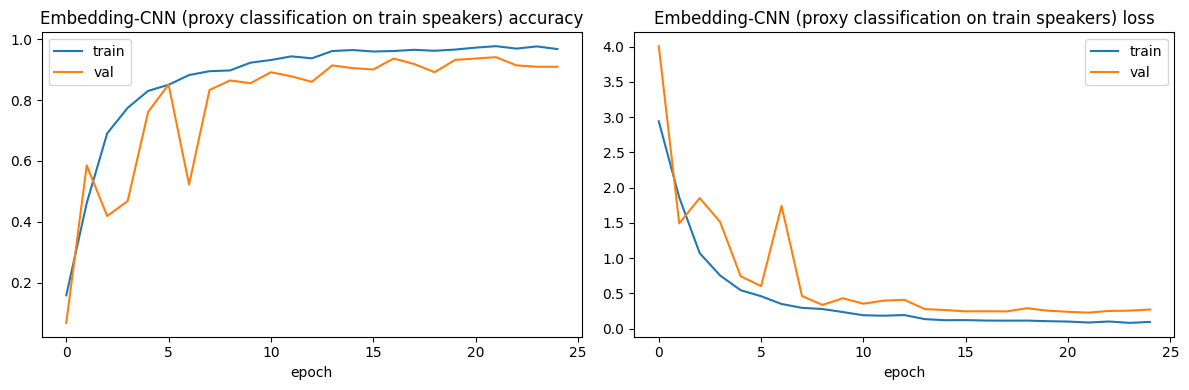

In [ ]:
label_names = le.inverse_transform(y_enc)

def mask_for(speaker_set):
    """"Returns a boolean mask selecting only the rows corresponding to the given speaker set"""
    return np.isin(label_names, list(speaker_set))

mask_train, mask_val, mask_test = mask_for(train_speakers), mask_for(val_speakers), mask_for(test_speakers)

X_mel_train_os, y_train_os = X_mel[mask_train], y_enc[mask_train]
X_mel_val_os, y_val_os, spk_val_os = X_mel[mask_val], y_enc[mask_val], label_names[mask_val]
X_mel_test_os, y_test_os, spk_test_os = X_mel[mask_test], y_enc[mask_test], label_names[mask_test]

# re-encode labels 0..n-1 restricted to the train-speaker subset (needed for the softmax proxy task)
le_open = LabelEncoder()
y_train_os_enc = le_open.fit_transform(label_names[mask_train])
num_train_speakers = len(le_open.classes_)

open_train_loader = DataLoader(SpectrogramDataset(X_mel_train_os, y_train_os_enc), batch_size=32, shuffle=True)

embed_model = SpeakerCNN(num_classes=num_train_speakers, embedding_dim=128).to(device)

# quick internal train/val split of the *train speakers* just to monitor the proxy classification task
idx = np.arange(len(y_train_os_enc))
idx_tr, idx_va = train_test_split(idx, test_size=0.15, stratify=y_train_os_enc, random_state=SEED)
proxy_train_loader = DataLoader(SpectrogramDataset(X_mel_train_os[idx_tr], y_train_os_enc[idx_tr]),
                                 batch_size=32, shuffle=True)
proxy_val_loader = DataLoader(SpectrogramDataset(X_mel_train_os[idx_va], y_train_os_enc[idx_va]),
                               batch_size=32, shuffle=False)

embed_history = train_model(embed_model, proxy_train_loader, proxy_val_loader, epochs=25)
plot_history(embed_history, "Embedding-CNN (proxy classification on train speakers)")


In [ ]:
# The trained CNN is used as a feature extractor
emb_val = get_embeddings(embed_model, X_mel_val_os)
emb_test = get_embeddings(embed_model, X_mel_test_os)

def cosine_sim(a, b):
    """Computes the cosine similarity between two sets of vectors `a` and `b` (2D arrays)"""
    a = a / (np.linalg.norm(a, axis=-1, keepdims=True) + 1e-8)
    b = b / (np.linalg.norm(b, axis=-1, keepdims=True) + 1e-8)
    return a @ b.T


### 6.2 Enrollment and verification trials

For every speaker in a split, a few utterances (`n_enroll`) are used to build an **enrollment template**
(mean embedding); the remaining utterances are used as **verification queries**. Each query is compared
against every enrolled template, producing genuine trials (query vs. own template) and impostor trials
(query vs. every other template).

In [ ]:
def build_trials(embeddings, speakers, n_enroll=3, rng=None, return_metadata=False):
    """Build genuine/impostor trials with reproducible enrollment/query assignments.

    If `return_metadata` is True, also return the query and template speaker for
    every score, which enables per-speaker error analysis without rebuilding the
    enrollment templates elsewhere.
    """
    if rng is None:
        rng = np.random.RandomState(SEED + n_enroll)

    speakers = np.array(speakers)
    unique_spk = np.unique(speakers)
    templates, query_embs, query_spk = {}, [], []

    for spk in unique_spk:
        spk_idx = np.where(speakers == spk)[0].copy()
        rng.shuffle(spk_idx)
        if len(spk_idx) <= n_enroll:
            continue  # not enough utterances to both enroll and query
        enroll_idx, query_idx = spk_idx[:n_enroll], spk_idx[n_enroll:]
        templates[spk] = embeddings[enroll_idx].mean(axis=0)
        query_embs.append(embeddings[query_idx])
        query_spk.extend([spk] * len(query_idx))

    query_embs = np.concatenate(query_embs, axis=0)
    query_spk = np.array(query_spk)
    template_spk = np.array(list(templates.keys()))
    template_embs = np.stack([templates[s] for s in template_spk])

    # Compute cosine similarity between each query embedding and all template embeddings
    # Each query is compared with every speaker template
    scores, genuine, trial_query_spk, trial_template_spk = [], [], [], []
    for q_emb, q_spk in zip(query_embs, query_spk):
        sims = cosine_sim(q_emb[None, :], template_embs)[0]
        for sim, t_spk in zip(sims, template_spk):
            scores.append(sim)
            genuine.append(int(t_spk == q_spk)) # 1 if genuine, 0 if impostor
            trial_query_spk.append(q_spk)
            trial_template_spk.append(t_spk)

    result = (np.array(scores), np.array(genuine))
    if return_metadata:
        return result + (np.array(trial_query_spk), np.array(trial_template_spk))
    return result

val_scores, val_genuine = build_trials(emb_val, spk_val_os, n_enroll=3)
test_scores, test_genuine = build_trials(emb_test, spk_test_os, n_enroll=3)

print(f"Validation trials: {len(val_scores)} ({val_genuine.sum()} genuine / "
      f"{len(val_scores) - val_genuine.sum()} impostor)")
print(f"Test trials: {len(test_scores)} ({test_genuine.sum()} genuine / "
      f"{len(test_scores) - test_genuine.sum()} impostor)")

Validation trials: 5350 (535 genuine / 4815 impostor)
Test trials: 4410 (441 genuine / 3969 impostor)


### 6.3 ROC curve and Equal Error Rate (EER)

The acceptance threshold is tuned on the **validation speakers** (to avoid any leakage from the test
speakers), then applied to the test speakers to report the final open-set verification performance.

Validation EER: 4.88%  (threshold = 0.878)
Test speakers (unseen) @ val-tuned threshold: accuracy=0.874  FAR=13.66%  FRR=3.40%


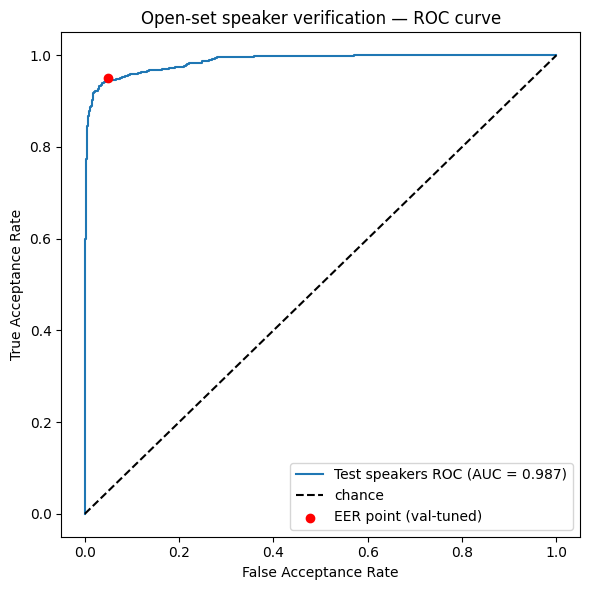

In [ ]:
def compute_eer(scores, genuine):
    """Computes the Equal Error Rate (EER) and the corresponding threshold for a set of scores and labels"""
    fpr, tpr, thresholds = roc_curve(genuine, scores)
    fnr = 1 - tpr
    eer_idx = np.nanargmin(np.abs(fnr - fpr))
    eer = (fpr[eer_idx] + fnr[eer_idx]) / 2
    eer_threshold = thresholds[eer_idx]
    return eer, eer_threshold, fpr, tpr

val_eer, val_threshold, val_fpr, val_tpr = compute_eer(val_scores, val_genuine)
print(f"Validation EER: {val_eer*100:.2f}%  (threshold = {val_threshold:.3f})")

# apply the threshold tuned on validation speakers to the (unseen) test speakers
test_pred = (test_scores >= val_threshold).astype(int)
test_far = ((test_pred == 1) & (test_genuine == 0)).sum() / max((test_genuine == 0).sum(), 1)
test_frr = ((test_pred == 0) & (test_genuine == 1)).sum() / max((test_genuine == 1).sum(), 1)
test_acc = accuracy_score(test_genuine, test_pred)

print(f"Test speakers (unseen) @ val-tuned threshold: "
      f"accuracy={test_acc:.3f}  FAR={test_far*100:.2f}%  FRR={test_frr*100:.2f}%")

test_fpr, test_tpr, _ = roc_curve(test_genuine, test_scores)
roc_auc = auc(test_fpr, test_tpr)

plt.figure(figsize=(6, 6))
plt.plot(test_fpr, test_tpr, label=f"Test speakers ROC (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="chance")
plt.scatter([val_fpr[np.nanargmin(np.abs((1 - val_tpr) - val_fpr))]],
            [val_tpr[np.nanargmin(np.abs((1 - val_tpr) - val_fpr))]],
            color="red", zorder=5, label="EER point (val-tuned)")
plt.xlabel("False Acceptance Rate"); plt.ylabel("True Acceptance Rate")
plt.title("Open-set speaker verification — ROC curve")
plt.legend(); plt.tight_layout(); plt.show()


### 6.3.1 Effect of `n_enroll` on EER

More enrollment utterances give a less noisy speaker template (mean embedding), which should
generally lower EER, at the cost of leaving fewer utterances available as queries per speaker.

In [35]:
n_enroll_sweep = [1, 3, 5]
eer_by_n_enroll = []

for n_enroll in n_enroll_sweep:
    # Keep enrollment/query assignments deterministic and independent across settings.
    sweep_rng = np.random.RandomState(SEED + 1000 + n_enroll)
    v_scores, v_genuine = build_trials(emb_val, spk_val_os, n_enroll=n_enroll, rng=sweep_rng)
    t_scores, t_genuine = build_trials(
        emb_test, spk_test_os, n_enroll=n_enroll,
        rng=np.random.RandomState(SEED + 2000 + n_enroll),
    )

    v_eer, v_threshold, _, _ = compute_eer(v_scores, v_genuine)

    t_pred = (t_scores >= v_threshold).astype(int)
    t_far = ((t_pred == 1) & (t_genuine == 0)).sum() / max((t_genuine == 0).sum(), 1)
    t_frr = ((t_pred == 0) & (t_genuine == 1)).sum() / max((t_genuine == 1).sum(), 1)

    eer_by_n_enroll.append({
        "n_enroll": n_enroll,
        "val_EER_%": round(v_eer * 100, 2),
        "test_FAR_%": round(t_far * 100, 2),
        "test_FRR_%": round(t_frr * 100, 2),
    })

eer_sweep_df = pd.DataFrame(eer_by_n_enroll)
eer_sweep_df

,n_enroll,val_EER_%,test_FAR_%,test_FRR_%
0,1,5.41,13.38,4.12
1,3,1.70,7.73,3.63
2,5,1.67,8.92,4.04


Per-speaker verification errors (highest FRR first):


,speaker,n_usable_utterances,rms_mean,silence_ratio_mean,FRR_%,FAR_%,genuine_trials,impostor_trials
1,Speaker0041,32,0.035,0.252,44.828,22.222,29,261
4,Speaker_0011,65,0.035,0.154,1.613,13.441,62,558
3,Speaker_0003,85,0.059,0.238,1.220,0.000,82,738
0,Speaker0034,34,0.037,0.228,0.000,31.541,31,279
2,Speaker0042,41,0.030,0.187,0.000,14.327,38,342
5,Speaker_0014,51,0.035,0.176,0.000,16.667,48,432
6,Speaker_0015,38,0.035,0.184,0.000,16.825,35,315
7,Speaker_0016,48,0.021,0.278,0.000,16.543,45,405
8,Speaker_0017,44,0.036,0.341,0.000,4.878,41,369
9,Speaker_0019,33,0.050,0.208,0.000,22.963,30,270


Descriptive correlations with per-speaker error rates:
                     FAR_%  FRR_%
n_usable_utterances -0.751 -0.285
rms_mean            -0.305 -0.053
silence_ratio_mean  -0.266  0.158
FAR_%                1.000  0.228
FRR_%                0.228  1.000


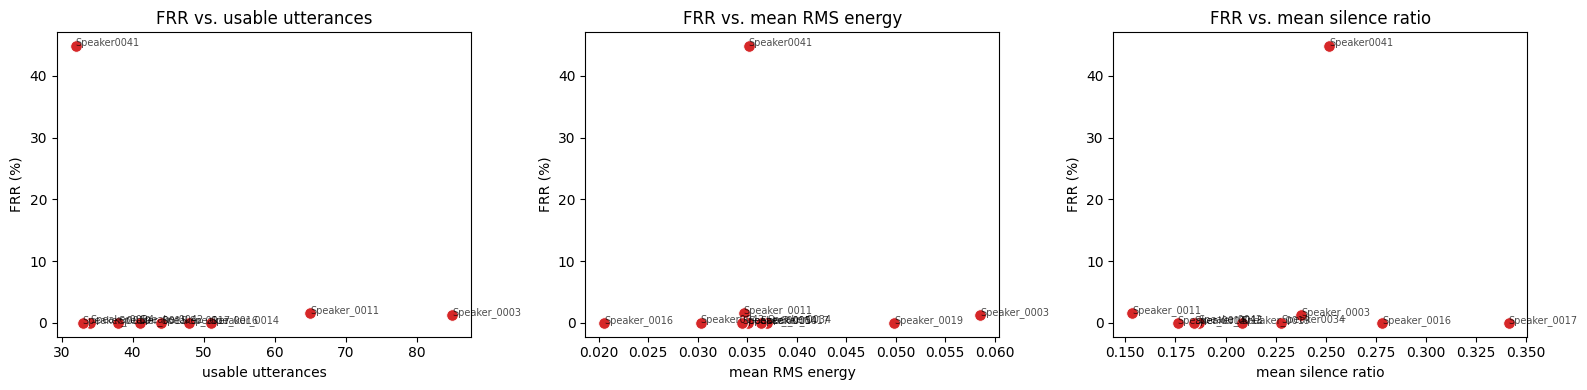

In [ ]:
# Per-speaker verification error analysis using the same n_enroll=3 protocol.
test_scores_meta, test_genuine_meta, trial_query_spk, trial_template_spk = build_trials(
    emb_test,
    spk_test_os,
    n_enroll=3,
    rng=np.random.RandomState(SEED + 3),
    return_metadata=True,
)

assert np.array_equal(test_scores_meta, test_scores)
assert np.array_equal(test_genuine_meta, test_genuine)

trial_pred = (test_scores_meta >= val_threshold).astype(int)
per_speaker_rows = []
for speaker in np.unique(trial_query_spk):
    query_mask = trial_query_spk == speaker
    genuine_mask = query_mask & (trial_template_spk == speaker)
    impostor_mask = query_mask & (trial_template_spk != speaker)
    speaker_quality = quality_df[quality_df["speaker"] == speaker]

    per_speaker_rows.append({
        "speaker": speaker,
        "n_usable_utterances": len(speaker_quality),
        "rms_mean": speaker_quality["rms_mean"].mean(),
        "silence_ratio_mean": speaker_quality["silence_ratio"].mean(),
        "FRR_%": 100 * np.mean(trial_pred[genuine_mask] == 0),
        "FAR_%": 100 * np.mean(trial_pred[impostor_mask] == 1),
        "genuine_trials": int(genuine_mask.sum()),
        "impostor_trials": int(impostor_mask.sum()),
    })

per_speaker_errors = pd.DataFrame(per_speaker_rows).sort_values("FRR_%", ascending=False)
print("Per-speaker verification errors (highest FRR first):")
display(per_speaker_errors.round(3))

print("Descriptive correlations with per-speaker error rates:")
print(per_speaker_errors[["n_usable_utterances", "rms_mean", "silence_ratio_mean", "FAR_%", "FRR_%"]]
      .corr()[["FAR_%", "FRR_%"]].round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, x, xlabel in zip(
    axes,
    ["n_usable_utterances", "rms_mean", "silence_ratio_mean"],
    ["usable utterances", "mean RMS energy", "mean silence ratio"],
):
    sn.scatterplot(data=per_speaker_errors, x=x, y="FRR_%", ax=ax, color="#d62728", s=70)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("FRR (%)")
    ax.set_title(f"FRR vs. {xlabel}")
    for _, row in per_speaker_errors.iterrows():
        ax.annotate(row["speaker"], (row[x], row["FRR_%"]), fontsize=7, alpha=0.7)
plt.tight_layout()
plt.show()


### 6.3.2 Case study: how one test speaker is treated during verification

The same idea as the Section 5.2.1 closed-set case study, applied to the open-set pipeline: rather
than reading the aggregate EER/FAR/FRR numbers, walk through what actually happens to one specific
**test speaker** -- someone the embedding CNN never saw during training -- as they get enrolled and
then verified.

- **Enrollment:** `n_enroll=3` of this speaker's utterances are averaged into a template embedding,
  exactly as in Section 6.2.
- **Genuine trial:** one of their *remaining* utterances (never used for enrollment) is compared
  against their own template.
- **Impostor trial:** that same query is also compared against a different test speaker's template.
- Both trials are checked against the validation-tuned threshold from Section 6.3 -- the same
  threshold used for the aggregate test-set numbers, applied here to one concrete case.

Test speaker (unseen during training): Speaker_0016
  Enrolled with 3 utterances -> template embedding (dim 128)
  45 remaining utterances held out as verification queries

Threshold (tuned on validation speakers): 0.878

Genuine trial  -- query vs. Speaker_0016's own template:  similarity = 0.972  -> ACCEPT
Impostor trial -- same query vs. Speaker_0003's template:  similarity = 0.391  -> REJECT


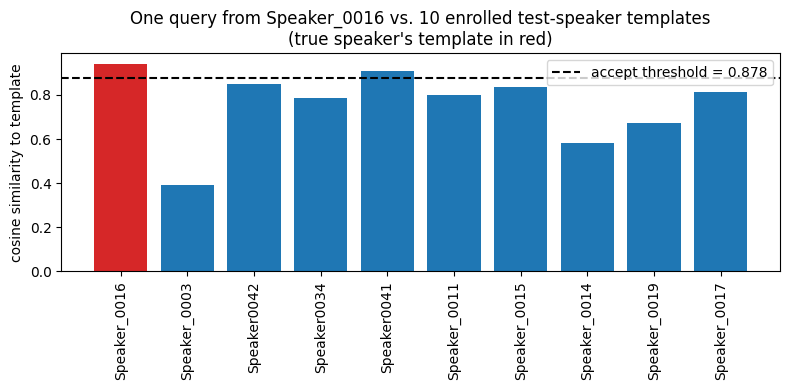

In [38]:
os_case_rng = np.random.RandomState(SEED)  # independent of `rng` above, for a reproducible demo pick
n_enroll_demo = 3

unique_test_speakers = np.unique(spk_test_os)
case_study_test_speaker = os_case_rng.choice(unique_test_speakers)

spk_idx = np.where(spk_test_os == case_study_test_speaker)[0]
os_case_rng.shuffle(spk_idx)
enroll_idx, query_idx = spk_idx[:n_enroll_demo], spk_idx[n_enroll_demo:]

enroll_template = emb_test[enroll_idx].mean(axis=0)
query_emb = emb_test[query_idx[0]]  # one held-out query utterance, never used for enrollment

genuine_sim = cosine_sim(query_emb[None, :], enroll_template[None, :])[0, 0]
genuine_decision = "ACCEPT" if genuine_sim >= val_threshold else "REJECT"

other_test_speakers = [s for s in unique_test_speakers if s != case_study_test_speaker]
impostor_speaker = os_case_rng.choice(other_test_speakers)
impostor_idx = np.where(spk_test_os == impostor_speaker)[0][:n_enroll_demo]
impostor_template = emb_test[impostor_idx].mean(axis=0)

impostor_sim = cosine_sim(query_emb[None, :], impostor_template[None, :])[0, 0]
impostor_decision = "ACCEPT" if impostor_sim >= val_threshold else "REJECT"

print(f"Test speaker (unseen during training): {case_study_test_speaker}")
print(f"  Enrolled with {n_enroll_demo} utterances -> template embedding (dim {enroll_template.shape[0]})")
print(f"  {len(query_idx)} remaining utterances held out as verification queries\n")
print(f"Threshold (tuned on validation speakers): {val_threshold:.3f}\n")
print(f"Genuine trial  -- query vs. {case_study_test_speaker}'s own template:  "
      f"similarity = {genuine_sim:.3f}  -> {genuine_decision}")
print(f"Impostor trial -- same query vs. {impostor_speaker}'s template:  "
      f"similarity = {impostor_sim:.3f}  -> {impostor_decision}")

# Visualize the same query against several enrolled templates at once
sample_other_speakers = list(os_case_rng.choice(other_test_speakers,
                                                  size=min(9, len(other_test_speakers)), replace=False))
sample_speakers = [case_study_test_speaker] + sample_other_speakers
sample_sims = []
for spk in sample_speakers:
    idx = np.where(spk_test_os == spk)[0][:n_enroll_demo]
    template = emb_test[idx].mean(axis=0)
    sample_sims.append(cosine_sim(query_emb[None, :], template[None, :])[0, 0])

colors = ["#d62728" if s == case_study_test_speaker else "#1f77b4" for s in sample_speakers]
plt.figure(figsize=(8, 4))
plt.bar(range(len(sample_speakers)), sample_sims, color=colors)
plt.axhline(val_threshold, color="black", linestyle="--", label=f"accept threshold = {val_threshold:.3f}")
plt.xticks(range(len(sample_speakers)), sample_speakers, rotation=90)
plt.ylabel("cosine similarity to template")
plt.title(f"One query from {case_study_test_speaker} vs. {len(sample_speakers)} enrolled test-speaker "
          f"templates\n(true speaker's template in red)")
plt.legend()
plt.tight_layout()
plt.show()


### 6.3.3 Baseline: statistical-feature embeddings

The CNN embedding is a learned representation. As a baseline, the same enrollment/verification
pipeline (`build_trials`, `compute_eer`) is rerun using the plain 128-d statistical feature vector
(`X_stat` - the same features SVM/RF use for closed-set) directly as the "embedding," standing in
for anything learned. 

One detail matters here: the closed-set `scaler` (Section 5.1) can't be reused. It was fit on the
closed-set *utterance-level* training split, which almost certainly includes utterances from speakers
who ended up in this open-set *test* group -- reusing it would leak information about exactly the
speakers this protocol is supposed to keep unseen. A fresh scaler is fit here on the open-set train
speakers only, mirroring how `embed_model` itself was trained only on them.

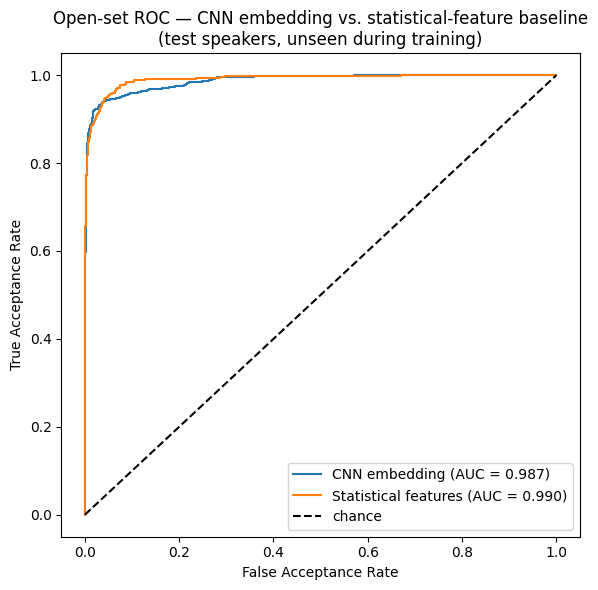

,embedding,val_EER_%,test_accuracy,test_FAR_%,test_FRR_%,test_AUC
0,CNN (learned),4.88,0.874,13.66,3.40,0.987
1,Statistical features (baseline),7.98,0.916,9.17,1.59,0.990


In [39]:
X_stat_train_os = X_stat[mask_train]
X_stat_val_os = X_stat[mask_val]
X_stat_test_os = X_stat[mask_test]

stat_scaler_os = StandardScaler()
stat_scaler_os.fit(X_stat_train_os)

emb_val_stat = stat_scaler_os.transform(X_stat_val_os)
emb_test_stat = stat_scaler_os.transform(X_stat_test_os)

val_scores_stat, val_genuine_stat = build_trials(emb_val_stat, spk_val_os, n_enroll=3)
test_scores_stat, test_genuine_stat = build_trials(emb_test_stat, spk_test_os, n_enroll=3)

val_eer_stat, val_threshold_stat, _, _ = compute_eer(val_scores_stat, val_genuine_stat)

test_pred_stat = (test_scores_stat >= val_threshold_stat).astype(int)
test_far_stat = ((test_pred_stat == 1) & (test_genuine_stat == 0)).sum() / max((test_genuine_stat == 0).sum(), 1)
test_frr_stat = ((test_pred_stat == 0) & (test_genuine_stat == 1)).sum() / max((test_genuine_stat == 1).sum(), 1)
test_acc_stat = accuracy_score(test_genuine_stat, test_pred_stat)

test_fpr_stat, test_tpr_stat, _ = roc_curve(test_genuine_stat, test_scores_stat)
roc_auc_stat = auc(test_fpr_stat, test_tpr_stat)

openset_comparison = pd.DataFrame([
    {"embedding": "CNN (learned)", "val_EER_%": round(val_eer * 100, 2),
     "test_accuracy": round(test_acc, 3), "test_FAR_%": round(test_far * 100, 2),
     "test_FRR_%": round(test_frr * 100, 2), "test_AUC": round(roc_auc, 3)},
    {"embedding": "Statistical features (baseline)", "val_EER_%": round(val_eer_stat * 100, 2),
     "test_accuracy": round(test_acc_stat, 3), "test_FAR_%": round(test_far_stat * 100, 2),
     "test_FRR_%": round(test_frr_stat * 100, 2), "test_AUC": round(roc_auc_stat, 3)},
])

plt.figure(figsize=(6, 6))
plt.plot(test_fpr, test_tpr, label=f"CNN embedding (AUC = {roc_auc:.3f})")
plt.plot(test_fpr_stat, test_tpr_stat, label=f"Statistical features (AUC = {roc_auc_stat:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="chance")
plt.xlabel("False Acceptance Rate"); plt.ylabel("True Acceptance Rate")
plt.title("Open-set ROC — CNN embedding vs. statistical-feature baseline\n(test speakers, unseen during training)")
plt.legend()
plt.tight_layout()
plt.show()

openset_comparison


**Sources**: Kaggle *Speaker Recognition Audio Dataset* (linked above); librosa documentation for feature
extraction; general speaker-embedding ("d-vector"/"x-vector") methodology from the speaker-recognition
literature; scikit-learn and PyTorch documentation for the classical ML and deep learning components.